In [ ]:
!pip install torch torchvision matplotlib

In [ ]:
import urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from PIL import Image
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| urządzenie:", device)

PyTorch: 2.14.1+cpu | urządzenie: cpu


In [ ]:
def out_dim(in_size, k, s=1, p=0, d=1):
    return (in_size + 2*p - d*(k-1) - 1)//s + 1

IN = 32
configs = [
    dict(k=3, s=1, p=0, d=1),
    dict(k=5, s=2, p=2, d=1),
    dict(k=3, s=2, p=1, d=2),
    dict(k=7, s=1, p=3, d=1),
    dict(k=5, s=1, p=4, d=2),
]

print(f"in={IN}")
print(f"{'k':>2} {'s':>2} {'p':>2} {'d':>2} | {'wzór':>5} {'Conv2d':>7}")
x = torch.randn(1, 3, IN, IN)
for c in configs:
    conv = nn.Conv2d(3, 8, kernel_size=c['k'], stride=c['s'], padding=c['p'], dilation=c['d'])
    real = conv(x).shape[-1]
    formula = out_dim(IN, **c)
    ok = '✓' if real == formula else 'X'
    print(f"{c['k']:>2} {c['s']:>2} {c['p']:>2} {c['d']:>2} | {formula:>5} {real:>7}   {ok}")

in=32
 k  s  p  d |  wzór  Conv2d
 3  1  0  1 |    30      30   ✓
 5  2  2  1 |    16      16   ✓
 3  2  1  2 |    15      15   ✓
 7  1  3  1 |    32      32   ✓
 5  1  4  2 |    32      32   ✓


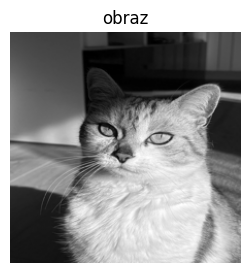

In [ ]:
pil = Image.open("zdjęcie_kot.jpg").convert("RGB").resize((224, 224))

rgb = torch.from_numpy(np.array(pil)).float().permute(2,0,1).unsqueeze(0) / 255.0
gray = rgb.mean(1, keepdim=True)

plt.figure(figsize=(3,3))
plt.imshow(gray[0,0], cmap="gray")
plt.axis("off")
plt.title("obraz")
plt.show()

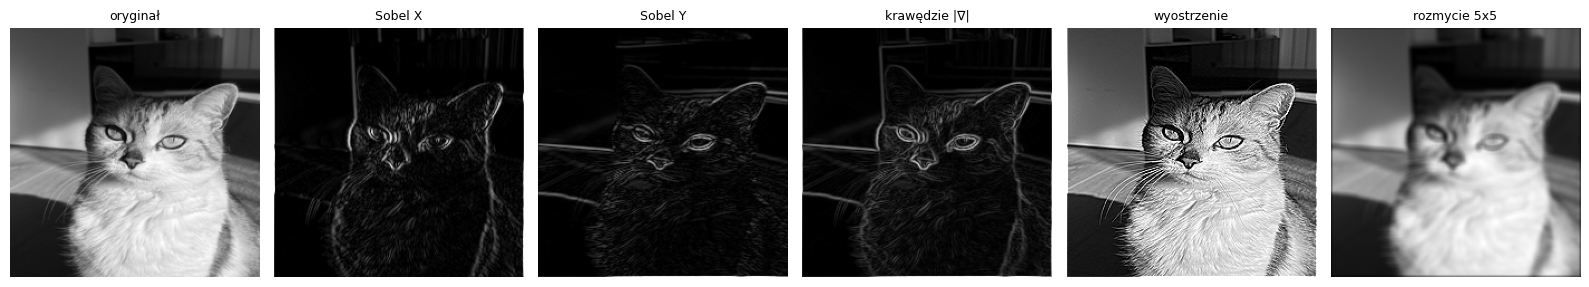

In [ ]:
def kernel(t):
    return torch.tensor(t, dtype=torch.float32).view(1,1,*np.array(t).shape)

sobel_x = kernel([[-1,0,1],[-2,0,2],[-1,0,1]])
sobel_y = kernel([[-1,-2,-1],[0,0,0],[1,2,1]])
sharpen = kernel([[0,-1,0],[-1,5,-1],[0,-1,0]])
blur = torch.ones(1,1,5,5)/25.0

gx = F.conv2d(gray, sobel_x, padding=1)
gy = F.conv2d(gray, sobel_y, padding=1)
edges = (gx**2 + gy**2).sqrt()
results = {
    "oryginał": gray,
    "Sobel X": gx.abs(),
    "Sobel Y": gy.abs(),
    "krawędzie |∇|": edges,
    "wyostrzenie": F.conv2d(gray, sharpen, padding=1).clamp(0,1),
    "rozmycie 5x5": F.conv2d(gray, blur, padding=2),
}
fig, axes = plt.subplots(1, len(results), figsize=(16, 3))
for ax, (name, out) in zip(axes, results.items()):
    m = out[0,0].detach()
    ax.imshow(m, cmap="gray"); ax.set_title(name, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

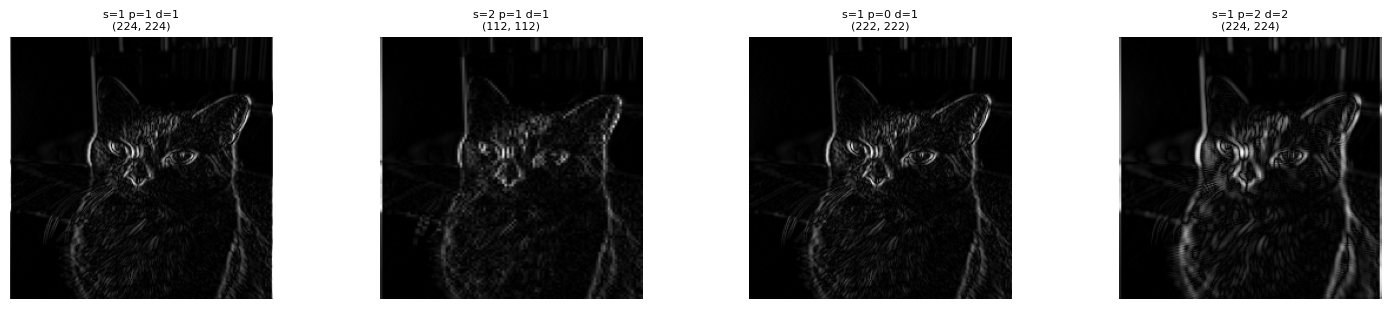

In [ ]:
settings = [
    dict(stride=1, padding=1, dilation=1),
    dict(stride=2, padding=1, dilation=1),
    dict(stride=1, padding=0, dilation=1),
    dict(stride=1, padding=2, dilation=2),
]
fig, axes = plt.subplots(1, len(settings), figsize=(15, 3.2))
for ax, s in zip(axes, settings):
    out = F.conv2d(gray, sobel_x, **s)
    ax.imshow(out[0,0].abs().detach(), cmap="gray")
    ax.set_title(f"s={s['stride']} p={s['padding']} d={s['dilation']}\n{tuple(out.shape[-2:])}", fontsize=8)
    ax.axis("off")
plt.tight_layout(); plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 124MB/s]


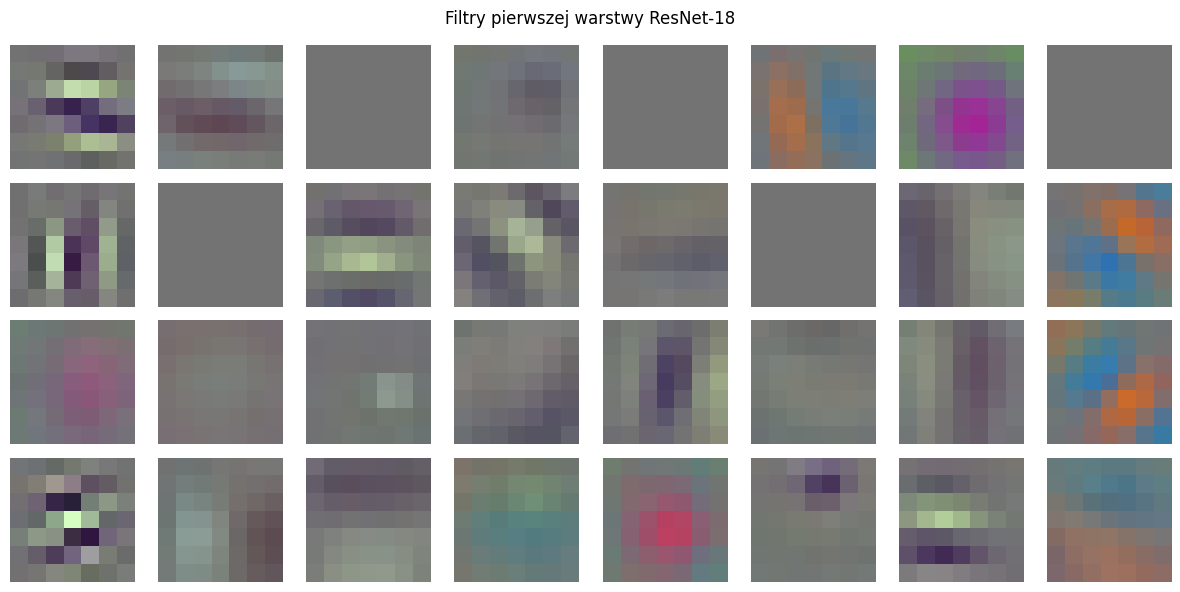

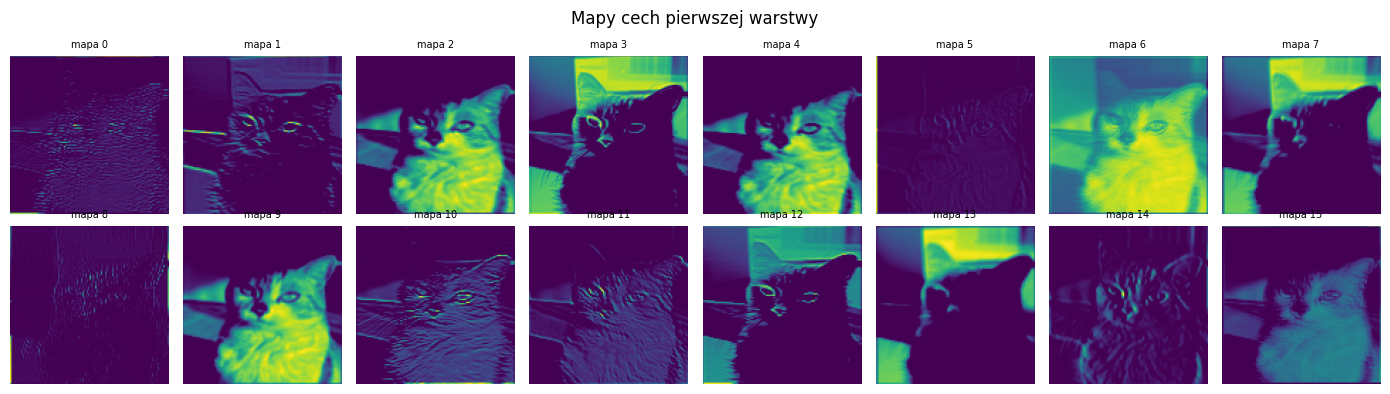

In [ ]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device).eval()

W = model.conv1.weight.data.clone().cpu()
Wn = (W - W.min()) / (W.max() - W.min())
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(Wn[i].permute(1,2,0)); ax.axis("off")
fig.suptitle("Filtry pierwszej warstwy ResNet-18"); plt.tight_layout(); plt.show()

preprocess = weights.transforms()
pil_gray_3ch = pil.convert("L").convert("RGB")
x = preprocess(pil_gray_3ch).unsqueeze(0).to(device)

with torch.no_grad():
    fmaps = torch.relu(model.conv1(x))[0].cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmaps[i], cmap="viridis"); ax.set_title(f"mapa {i}", fontsize=7); ax.axis("off")
fig.suptitle("Mapy cech pierwszej warstwy"); plt.tight_layout(); plt.show()

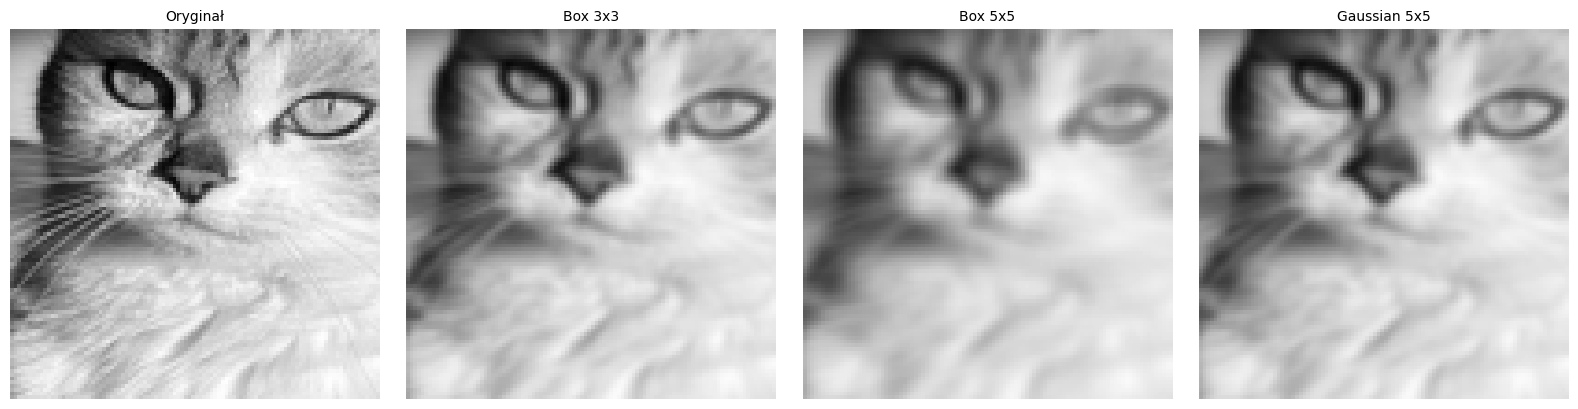

In [ ]:
box_3x3 = torch.ones(1, 1, 3, 3) / 9.0
box_5x5 = torch.ones(1, 1, 5, 5) / 25.0

vec = torch.tensor([1., 4., 6., 4., 1.])
gauss_2d = vec.view(5, 1) @ vec.view(1, 5)
gauss_5x5 = gauss_2d.view(1, 1, 5, 5) / 256.0

out_box3 = F.conv2d(gray, box_3x3, padding=1)
out_box5 = F.conv2d(gray, box_5x5, padding=2)
out_gauss5 = F.conv2d(gray, gauss_5x5, padding=2)

y1, y2, x1, x2 = 80, 180, 60, 160

crop_orig = gray[0, 0, y1:y2, x1:x2].detach()
crop_box3 = out_box3[0, 0, y1:y2, x1:x2].detach()
crop_box5 = out_box5[0, 0, y1:y2, x1:x2].detach()
crop_gauss = out_gauss5[0, 0, y1:y2, x1:x2].detach()

vmin, vmax = crop_orig.min(), crop_orig.max()

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
images = [crop_orig, crop_box3, crop_box5, crop_gauss]
titles = ["Oryginał", "Box 3x3", "Box 5x5", "Gaussian 5x5"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img, cmap="gray", vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()